In [27]:
from google.colab import files
uploaded = files.upload()

Saving uber.csv to uber (1).csv


In [28]:
df = pd.read_csv("uber.csv")

df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


Shape: (200000, 9)
Nulls:
 Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


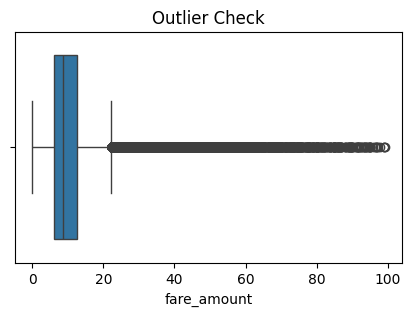

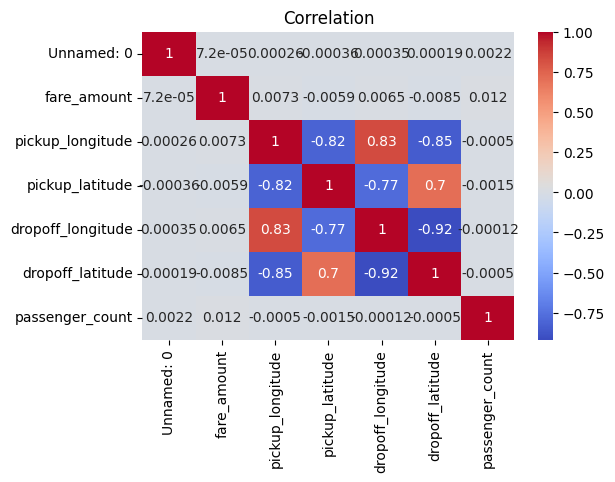

In [29]:
# ALL IMPORTS IN ONE PLACE - No Error
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

# 1. Load Data
df = pd.read_csv("uber.csv") # Or use your path
print("Shape:", df.shape)
print("Nulls:\n", df.isnull().sum())

# 2. Pre-process + Remove Nulls & Invalid Fares
df = df.dropna()
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] < 100)]

# 3. Outlier Check
plt.figure(figsize=(5,3))
sns.boxplot(x=df['fare_amount'])
plt.title('Outlier Check')
plt.show()

# 4. Correlation
numeric_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(6,4))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation')
plt.show()

In [30]:
# Features = input, Target = price we want to predict
X = df[['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']]
y = df['fare_amount']

# Split - 80% for teaching model, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Linear Regression
model1 = LinearRegression()
model1.fit(X_train, y_train) # Teach
pred1 = model1.predict(X_test) # Predict
print("Linear R2:", r2_score(y_test, pred1), " RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))

# 2. Ridge Regression
model2 = Ridge()
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)
print("Ridge R2:", r2_score(y_test, pred2), " RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))

# 3. Lasso Regression
model3 = Lasso()
model3.fit(X_train, y_train)
pred3 = model3.predict(X_test)
print("Lasso R2:", r2_score(y_test, pred3), " RMSE:", np.sqrt(mean_squared_error(y_test, pred3)))

Linear R2: -0.00012162518764657904  RMSE: 9.343338643772022
Ridge R2: -0.0001216248193265379  RMSE: 9.343338642051561
Lasso R2: -3.0185802839310938e-05  RMSE: 9.342911511388857
